# Character-Level RNN for Name Classification

This notebook demonstrates how to build and train a character-level Recurrent Neural Network (RNN) using PyTorch to classify names into their country of origin. This is a classic NLP task built from scratch without using PyTorch's built-in RNN classes.

## 1. Setup & Data Loading

In [ ]:
import torch
import torch.nn as nn
import matplotlib.pyplot as plt

import importlib

utils = importlib.import_module("07_utils")
ALL_LETTERS = utils.ALL_LETTERS
N_LETTERS = utils.N_LETTERS
load_data = utils.load_data
letter_to_tensor = utils.letter_to_tensor
line_to_tensor = utils.line_to_tensor
random_training_example = utils.random_training_example

In [ ]:
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

## 2. Model Architecture

We define a custom RNN cell that takes an input tensor and a hidden state, processes them through two linear layers (`i2h` for the next hidden state, and `i2o` for the output prediction), and uses `LogSoftmax` to output class log-probabilities.

In [ ]:
device

device(type='cuda')

In [ ]:
class RNN(nn.Module):
    def __init__(self, input_size, hidden_size, output_size):
        super(RNN, self).__init__()

        self.hidden_size = hidden_size
        self.i2h = nn.Linear(input_size + hidden_size, hidden_size)
        self.i20 = nn.Linear(input_size + hidden_size, output_size)
        self.softmax = nn.LogSoftmax(dim = 1)

    def forward(self, input_tensor, hidden_tensor):
        combined = torch.cat((input_tensor, hidden_tensor), dim=1)

        hidden = self.i2h(combined)
        output = self.i20(combined)
        output = self.softmax(output)

        return output, hidden

    def init_hidden(self):
        return torch.zeros(1, self.hidden_size)

In [ ]:
category_lines, all_categories = load_data()
n_categories = len(all_categories)
print(n_categories)

18


## 3. Training Preparation & Examples

In [ ]:
n_hidden = 128 #hyperparameter
rnn = RNN(N_LETTERS, n_hidden, n_categories).to(device)

In [ ]:
#single step
input_tensor = letter_to_tensor('A').to(device)

hidden_tensor = rnn.init_hidden().to(device)

output, next_hidden = rnn(input_tensor, hidden_tensor)
print(output.size())
print(next_hidden.size())

torch.Size([1, 18])
torch.Size([1, 128])


In [ ]:
# whole sequence/name
input_tensor = line_to_tensor('Albert').to(device)
hidden_tensor = rnn.init_hidden().to(device)

output, next_hidden = rnn(input_tensor[0], hidden_tensor)
print(output.size())
print(next_hidden.size())

torch.Size([1, 18])
torch.Size([1, 128])


In [ ]:
def category_from_output(output):
    category_idx = torch.argmax(output).item()
    return all_categories[category_idx]

In [ ]:
print(category_from_output(output))

Czech


In [ ]:
criterion = nn.NLLLoss()
learning_rate = 0.005
optimizer = torch.optim.SGD(rnn.parameters(), lr=learning_rate)

def train(line_tensor, category_tensor):

    # Move tensors to the GPU right inside the function
    line_tensor = line_tensor.to(device)
    category_tensor = category_tensor.to(device)
    hidden = rnn.init_hidden().to(device)

    for i in range(line_tensor.size()[0]):
        output, hidden = rnn(line_tensor[i], hidden)

    loss = criterion(output, category_tensor)

    optimizer.zero_grad()
    loss.backward()
    optimizer.step()

    return output, loss.item()

## 4. Training Loop

We train the network using Stochastic Gradient Descent (SGD) and Negative Log-Likelihood Loss (NLLLoss).

In [ ]:
current_loss = 0
all_losses = []

plot_steps, print_steps = 1000, 5000
n_iters = 100000

for i in range(n_iters):
    category, line, category_tensor, line_tensor = random_training_example(category_lines, all_categories)

    output, loss = train(line_tensor, category_tensor)
    current_loss += loss

    if (i+1) % plot_steps == 0:
        all_losses.append(current_loss)
        current_loss = 0

    if (i+1) % print_steps == 0:
        guess = category_from_output(output)
        correct = "CORRECT" if guess == category else f"WRONG ({category})"
        print(f"{i+1} {(i+1)/n_iters*100} {loss:.4f} {line} / {guess} {correct}")

5000 5.0 3.0225 Holan / Irish WRONG (Czech)
10000 10.0 1.5897 To / Vietnamese CORRECT
15000 15.0 1.9799 Tremble / Portuguese WRONG (French)
20000 20.0 0.7211 Shim / Korean CORRECT
25000 25.0 3.4778 Mojjis / Greek WRONG (Czech)
30000 30.0 2.6457 O'Donnell / Scottish WRONG (Irish)
35000 35.0 2.4820 Stites / Dutch WRONG (Czech)
40000 40.0 0.9428 Vygodin / Russian CORRECT
45000 45.0 0.1539 Yoshizaki / Japanese CORRECT
50000 50.0 0.5881 Eng / Chinese CORRECT
55000 55.00000000000001 0.4561 Huan / Chinese CORRECT
60000 60.0 1.0857 Peeters / Dutch CORRECT
65000 65.0 1.9711 Sum / Korean WRONG (Chinese)
70000 70.0 1.4275 Worsnop / English CORRECT
75000 75.0 4.5948 Tourna / Spanish WRONG (Greek)
80000 80.0 0.5209 Penders / Dutch CORRECT
85000 85.0 0.4524 Yoo / Korean CORRECT
90000 90.0 0.2976 Choe / Korean CORRECT
95000 95.0 0.9853 Mohan / Irish CORRECT
100000 100.0 3.8072 Park  / Czech WRONG (Korean)


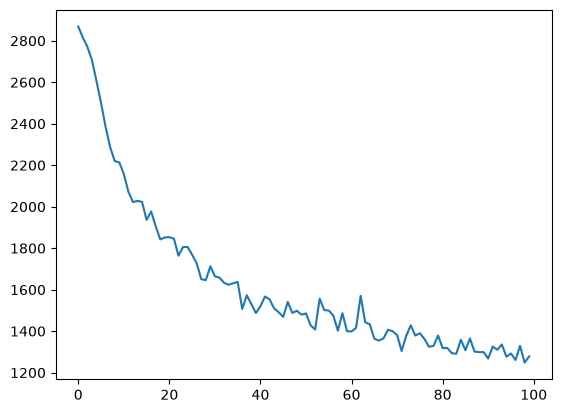

In [ ]:
plt.figure()
plt.plot(all_losses)
plt.show()

## 5. Inference & Evaluation

In [ ]:
def predict(input_line):
    print(f"\n> {input_line}")
    with torch.no_grad():
        line_tensor = line_to_tensor(input_line).to(device)
        hidden = rnn.init_hidden().to(device)

        for i in range(line_tensor.size()[0]):
            output, hidden = rnn(line_tensor[i], hidden)

        guess = category_from_output(output)
        print(guess)

In [ ]:
while True:
    sentence = input("Input:")
    if sentence == "quit":
        break

    predict(sentence)

Input: Sharapova



> Sharapova
Czech


Input: Agassi



> Agassi
Arabic


Input: Zhurkov


...

Input: penders



> penders
Dutch


Input: Courtous



> Courtous
Portuguese


Input: quit


## 6. Project Summary

- **Objective**: Classify surnames into 18 distinct language categories using a character-level RNN.
- **Data Representation**: Names are converted to tensors on a character-by-character basis using One-Hot encoding over all valid characters (`ALL_LETTERS`).
- **Model**: A custom-built PyTorch `nn.Module` implementing an RNN structure that updates its hidden state step-by-step through a sequence.
- **Optimization**: Trained using SGD with NLLLoss, achieving a steady convergence curve as visualized in the loss plot.